In [1]:
from google.colab import files
uploaded = files.upload()

Saving b6167dcf878645dab445c8328c514135.jpg to b6167dcf878645dab445c8328c514135.jpg


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

filename = list(uploaded.keys())[0]
image = cv2.imread(filename)

if image is None:
    raise ValueError("Unable to read image")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

In [3]:
gray_float = np.float32(gray)

corners = cv2.cornerHarris(
    gray_float,
    2,
    3,
    0.04
)

# Dilate corner points
corners = cv2.dilate(corners, None)

# Mark detected corners in red
result = image_rgb.copy()
result[corners > 0.01 * corners.max()] = [255, 0, 0]

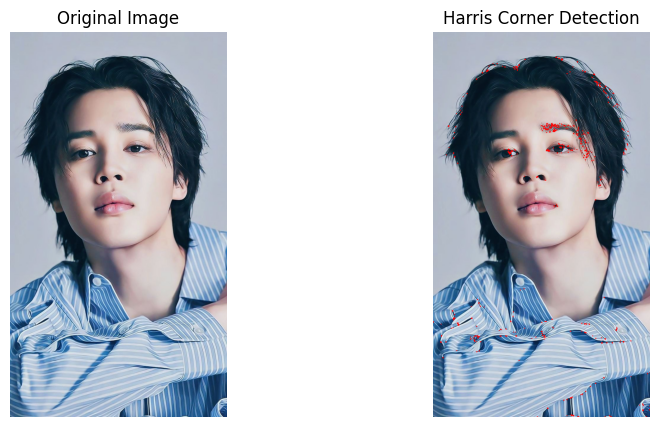

In [4]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(result)
plt.title("Harris Corner Detection")
plt.axis("off")

plt.show()